# A3: Predicting Car Price III (classification)

The same cleaned dataset, but the price is turned into **4 classes** (0 = cheapest quarter …
3 = most expensive quarter). We implement multinomial Logistic Regression from scratch with
classification metrics and an optional Ridge (L2) penalty, track experiments on the **CSIM MLflow
server**, and register the best model as `<student_ID>-a3-model` in *Staging*.

**Before running:** set your student ID in the cell below. To log to the CSIM server you must be on
the CSIM network (or VPN).

In [3]:
# !curl -s -o /dev/null -w "%{http_code}\n" -u student:________________ https://mlflow.ml.brain.cs.ait.ac.th

In [4]:
import os
STUDENT_ID = os.environ.get('STUDENT_ID', 'st127120')
# CSIM server: 'http://mlflow.ml.brain.cs.ait.ac.th/'. Falls back to a local file when not set,
# so the notebook also runs off-campus.
MLFLOW_URI = os.environ.get('MLFLOW_TRACKING_URI', 'sqlite:///mlflow.db')
print(STUDENT_ID, MLFLOW_URI)

st127120 sqlite:///mlflow.db


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, itertools, warnings
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)

## 1. Data cleaning (same rules as A1/A2)

In [6]:
df = pd.read_csv('cars.csv')
owner_map = {'First Owner': 1, 'Second Owner': 2, 'Third Owner': 3,
             'Fourth & Above Owner': 4, 'Test Drive Car': 5}
df['owner'] = df['owner'].map(owner_map)
df = df[~df['fuel'].isin(['CNG', 'LPG'])]
df['mileage'] = df['mileage'].str.split(' ').str[0].astype(float)
df['engine'] = df['engine'].str.split(' ').str[0].astype(float)
df['max_power'] = pd.to_numeric(df['max_power'].str.split(' ').str[0], errors='coerce')
df['brand'] = df['name'].str.split(' ').str[0]
df = df.drop(columns=['name', 'torque'])
df = df[df['owner'] != 5].reset_index(drop=True)
print(df.shape)

(8028, 12)


## 2. Turn the price into 4 classes

`pd.cut` needs bin edges; we use the price quartiles as edges, so each class holds about a quarter
of the cars. (Equal-width bins would put almost every car in class 0, because a few cars cost 10M.)

In [7]:
edges = df['selling_price'].quantile([0, .25, .5, .75, 1]).to_numpy(copy=True)
edges[0], edges[-1] = 0, np.inf                      # make sure every price falls in a bin
df['price_class'] = pd.cut(df['selling_price'], bins=edges, labels=[0, 1, 2, 3]).astype(int)
for c in range(4):
    print(f'class {c}: {edges[c]:>12,.0f} - {edges[c + 1]:>12,.0f}   n = {(df.price_class == c).sum()}')

class 0:            0 -      260,000   n = 2050
class 1:      260,000 -      450,000   n = 2044
class 2:      450,000 -      680,000   n = 1943
class 3:      680,000 -          inf   n = 1991


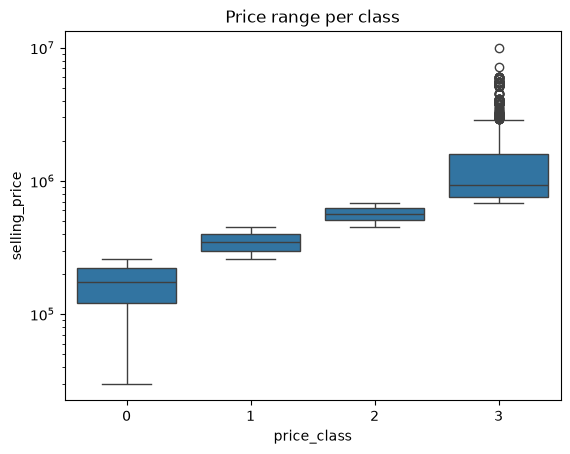

In [8]:
sns.boxplot(data=df, x='price_class', y='selling_price').set_yscale('log')
plt.title('Price range per class'); plt.show()

## 3. Split, impute, encode, scale (training statistics only)

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['selling_price', 'price_class'])
y = df['price_class'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train)

num_cols = ['year', 'km_driven', 'owner', 'mileage', 'engine', 'max_power', 'seats']
cat_cols = ['fuel', 'seller_type', 'transmission', 'brand']
fill_values = {c: X_train[c].median() for c in num_cols}
fill_values['seats'] = X_train['seats'].mode()[0]
fill_values.update({c: X_train[c].mode()[0] for c in cat_cols})

def encode(d):
    return pd.get_dummies(d.fillna(fill_values), columns=cat_cols, drop_first=True, dtype=int)

X_train_enc = encode(X_train)
X_val_enc = encode(X_val).reindex(columns=X_train_enc.columns, fill_value=0)
X_test_enc = encode(X_test).reindex(columns=X_train_enc.columns, fill_value=0)

scaler = StandardScaler()
X_train_enc[num_cols] = scaler.fit_transform(X_train_enc[num_cols])
X_val_enc[num_cols] = scaler.transform(X_val_enc[num_cols])
X_test_enc[num_cols] = scaler.transform(X_test_enc[num_cols])

feature_names = list(X_train_enc.columns)
X_tr, X_va, X_te = (d.values.astype(float) for d in (X_train_enc, X_val_enc, X_test_enc))
print(X_tr.shape, X_va.shape, X_te.shape)

(5137, 40) (1285, 40) (1606, 40)


## 4. The `LogisticRegression` class

Written to `logistic_regression.py` so the web app and the unit tests import the same code.

- **Ridge penalty** adds `λ Σθ²` to the loss and `2λθ` to the gradient (bias excluded).
- **precision_c** = TP / (TP + FP): of the cars we *called* class c, how many really are.
- **recall_c** = TP / (TP + FN): of the cars that *are* class c, how many we found.
- **f1_c** = harmonic mean of the two.
- **macro** averages treat every class equally; **weighted** averages weight each class by its share
  of the true labels. The brief's formula also divides by 4, but the weights already sum to 1, so we
  do not (this is what sklearn does, and the comparison below confirms it).

In [10]:
%%writefile logistic_regression.py
"""Multinomial Logistic Regression from scratch (based on 02 - Multinomial Logistic Regression.ipynb).

Additions for A3:
  * accuracy, precision, recall, f1 (per class)
  * macro_* and weighted_* averages, and a classification_report() like sklearn's
  * optional Ridge (L2) penalty: J = -sum(y log h) + lambda * sum(theta_j^2)
"""
import numpy as np
import pandas as pd


class LogisticRegression:
    def __init__(self, k, n, method='batch', lr=0.01, max_iter=5000, batch_size=64,
                 penalty=None, lam=0.01, seed=42):
        """
        k        : number of classes      n : number of features (without the bias)
        method   : 'batch', 'minibatch' or 'sto'
        lr       : learning rate          max_iter : number of gradient steps
        penalty  : None or 'ridge'        lam      : strength of the ridge penalty
        """
        assert method in ('batch', 'minibatch', 'sto')
        assert penalty in (None, 'ridge')
        self.k, self.n = k, n
        self.method, self.lr, self.max_iter, self.batch_size = method, lr, max_iter, batch_size
        self.penalty, self.lam, self.seed = penalty, lam, seed

    # ---------- training ----------
    @staticmethod
    def _add_bias(X):
        X = np.asarray(X, dtype=float)
        return np.hstack([np.ones((X.shape[0], 1)), X])

    @staticmethod
    def softmax(z):
        z = z - z.max(axis=1, keepdims=True)  # subtract the row max for numerical stability
        e = np.exp(z)
        return e / e.sum(axis=1, keepdims=True)

    def h_theta(self, X, W):
        return self.softmax(X @ W)

    def _one_hot(self, y):
        Y = np.zeros((len(y), self.k))
        Y[np.arange(len(y)), np.asarray(y, dtype=int)] = 1
        return Y

    def gradient(self, X, Y):
        m = X.shape[0]
        h = self.h_theta(X, self.W)
        loss = -np.sum(Y * np.log(h + 1e-12)) / m
        grad = X.T @ (h - Y) / m
        if self.penalty == 'ridge':
            # the bias row (row 0) is not penalised
            loss += self.lam * np.sum(self.W[1:] ** 2)
            reg = 2 * self.lam * self.W
            reg[0] = 0
            grad += reg
        return loss, grad

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        X, Y = self._add_bias(X), self._one_hot(y)
        self.W = np.zeros((X.shape[1], self.k))
        self.losses = []
        for i in range(self.max_iter):
            if self.method == 'batch':
                Xb, Yb = X, Y
            else:
                size = self.batch_size if self.method == 'minibatch' else 1
                idx = rng.choice(X.shape[0], size=size, replace=False)
                Xb, Yb = X[idx], Y[idx]
            loss, grad = self.gradient(Xb, Yb)
            self.W -= self.lr * grad
            if i % 100 == 0:
                self.losses.append(loss)
        return self

    def predict_proba(self, X):
        return self.h_theta(self._add_bias(X), self.W)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    # ---------- metrics ----------
    # TP_c: predicted c and really c ; FP_c: predicted c but not c ; FN_c: really c but predicted other
    def _counts(self, y_true, y_pred, c):
        y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        return tp, fp, fn

    def accuracy(self, y_true, y_pred):
        return np.mean(np.asarray(y_true) == np.asarray(y_pred))

    def precision(self, y_true, y_pred, c):
        tp, fp, _ = self._counts(y_true, y_pred, c)
        return tp / (tp + fp) if tp + fp > 0 else 0.0  # no predictions of c -> 0 (as sklearn)

    def recall(self, y_true, y_pred, c):
        tp, _, fn = self._counts(y_true, y_pred, c)
        return tp / (tp + fn) if tp + fn > 0 else 0.0

    def f1(self, y_true, y_pred, c):
        p, r = self.precision(y_true, y_pred, c), self.recall(y_true, y_pred, c)
        return 2 * p * r / (p + r) if p + r > 0 else 0.0

    def _per_class(self, metric, y_true, y_pred):
        return np.array([metric(y_true, y_pred, c) for c in range(self.k)])

    # macro: plain average over classes (every class counts the same)
    def macro_precision(self, y_true, y_pred):
        return self._per_class(self.precision, y_true, y_pred).mean()

    def macro_recall(self, y_true, y_pred):
        return self._per_class(self.recall, y_true, y_pred).mean()

    def macro_f1(self, y_true, y_pred):
        return self._per_class(self.f1, y_true, y_pred).mean()

    # weighted: average weighted by each class's share of the true labels (bigger classes count more).
    # The weights already sum to 1, so we do not divide by k again (this matches sklearn).
    def _weights(self, y_true):
        return np.array([np.mean(np.asarray(y_true) == c) for c in range(self.k)])

    def weighted_precision(self, y_true, y_pred):
        return np.sum(self._weights(y_true) * self._per_class(self.precision, y_true, y_pred))

    def weighted_recall(self, y_true, y_pred):
        return np.sum(self._weights(y_true) * self._per_class(self.recall, y_true, y_pred))

    def weighted_f1(self, y_true, y_pred):
        return np.sum(self._weights(y_true) * self._per_class(self.f1, y_true, y_pred))

    def classification_report(self, y_true, y_pred):
        """Same layout as sklearn.metrics.classification_report, as a DataFrame."""
        support = np.array([np.sum(np.asarray(y_true) == c) for c in range(self.k)])
        rows = {str(c): [self.precision(y_true, y_pred, c), self.recall(y_true, y_pred, c),
                         self.f1(y_true, y_pred, c), support[c]] for c in range(self.k)}
        n = support.sum()
        rows['accuracy'] = [np.nan, np.nan, self.accuracy(y_true, y_pred), n]
        rows['macro avg'] = [self.macro_precision(y_true, y_pred), self.macro_recall(y_true, y_pred),
                             self.macro_f1(y_true, y_pred), n]
        rows['weighted avg'] = [self.weighted_precision(y_true, y_pred), self.weighted_recall(y_true, y_pred),
                                self.weighted_f1(y_true, y_pred), n]
        return pd.DataFrame(rows, index=['precision', 'recall', 'f1-score', 'support']).T

Overwriting logistic_regression.py


In [11]:
from logistic_regression import LogisticRegression

## 5. Check our metrics against sklearn's `classification_report` (mock data)

In [12]:
from sklearn.metrics import classification_report
rng = np.random.default_rng(0)
y_mock_true = rng.integers(0, 4, 200)
y_mock_pred = np.where(rng.random(200) < 0.7, y_mock_true, rng.integers(0, 4, 200))  # ~70% right

ours = LogisticRegression(k=4, n=1).classification_report(y_mock_true, y_mock_pred)
print('Ours:'); display(ours.round(4))
print('sklearn:'); print(classification_report(y_mock_true, y_mock_pred, digits=4))

Ours:


,precision,recall,f1-score,support
0,0.7442,0.7619,0.7529,42.0
1,0.6471,0.7021,0.6735,47.0
2,0.6538,0.6538,0.6538,52.0
3,0.7778,0.7119,0.7434,59.0
accuracy,NaN,NaN,0.7050,200.0
macro avg,0.7057,0.7074,0.7059,200.0
weighted avg,0.7078,0.7050,0.7057,200.0


sklearn:
              precision    recall  f1-score   support

           0     0.7442    0.7619    0.7529        42
           1     0.6471    0.7021    0.6735        47
           2     0.6538    0.6538    0.6538        52
           3     0.7778    0.7119    0.7434        59

    accuracy                         0.7050       200
   macro avg     0.7057    0.7074    0.7059       200
weighted avg     0.7078    0.7050    0.7057       200



In [13]:
sk = pd.DataFrame(classification_report(y_mock_true, y_mock_pred, output_dict=True)).T
cols = ['precision', 'recall', 'f1-score']
diff = (ours.loc[['0', '1', '2', '3', 'macro avg', 'weighted avg'], cols].values
        - sk.loc[['0', '1', '2', '3', 'macro avg', 'weighted avg'], cols].values)
print('largest difference:', np.abs(diff).max())

largest difference: 1.1102230246251565e-16


**What does `support` mean?** It is the number of true samples of each class in `y_true`, i.e. how
many examples each row of the report is computed from. It is not a score; it tells you how much to
trust each row (a class with support 5 gives a noisy precision) and it is the weight used in the
*weighted avg* row.

## 6. Experiments, tracked in MLflow

Grid: method (batch, minibatch, sto) × learning rate (0.1, 0.01, 0.001) × penalty (none, ridge
λ = 0.01) = 18 runs. Each run is trained on the training set and scored on the validation set.
Every run logs its parameters, metrics and the model itself (not the dataset).

In [14]:
import mlflow
import mlflow.pyfunc
import logging
logging.getLogger('mlflow').setLevel(logging.ERROR)   # hide MLflow's deprecation chatter

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(f'{STUDENT_ID}-a3')

class CarPriceClassifier(mlflow.pyfunc.PythonModel):
    """Wraps our class so MLflow can save, register and serve it.
    Input: the encoded + scaled feature matrix. Output: class 0-3."""
    def __init__(self, model):
        self.model = model
    def predict(self, context, model_input):
        return self.model.predict(np.asarray(model_input, dtype=float))

grid = {'method': ['batch', 'minibatch', 'sto'], 'lr': [0.1, 0.01, 0.001], 'penalty': [None, 'ridge']}
results = []
for method, lr, penalty in itertools.product(*grid.values()):
    model = LogisticRegression(k=4, n=X_tr.shape[1], method=method, lr=lr, penalty=penalty, lam=0.01)
    model.fit(X_tr, y_train)
    p = model.predict(X_va)
    metrics = {'val_accuracy': model.accuracy(y_val, p), 'val_macro_f1': model.macro_f1(y_val, p),
               'val_weighted_f1': model.weighted_f1(y_val, p),
               'val_weighted_precision': model.weighted_precision(y_val, p),
               'val_weighted_recall': model.weighted_recall(y_val, p)}
    with mlflow.start_run(run_name=f'{method}-lr{lr}-{penalty or "none"}') as run:
        mlflow.log_params({'method': method, 'lr': lr, 'penalty': penalty or 'none', 'lambda': 0.01,
                           'max_iter': model.max_iter})
        mlflow.log_metrics(metrics)
        mlflow.pyfunc.log_model(artifact_path='model',  # 'name=' in MLflow 3, artifact_path works on 2.x too
                                 python_model=CarPriceClassifier(model),
                                code_paths=['logistic_regression.py'],
                                input_example=X_va[:2])
        results.append({'run_id': run.info.run_id, 'method': method, 'lr': lr,
                        'penalty': penalty or 'none', **metrics})

results = pd.DataFrame(results).sort_values('val_macro_f1', ascending=False)
results.drop(columns='run_id').round(4)

/home/utsb/.app/Python-Venv/venv/lib64/python3.14/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


,method,lr,penalty,val_accuracy,val_macro_f1,val_weighted_f1,val_weighted_precision,val_weighted_recall
0,batch,0.100,none,0.7518,0.7534,0.7543,0.7585,0.7518
6,minibatch,0.100,none,0.7486,0.7507,0.7516,0.7564,0.7486
8,minibatch,0.010,none,0.7160,0.7166,0.7176,0.7198,0.7160
1,batch,0.100,ridge,0.7136,0.7138,0.7149,0.7167,0.7136
2,batch,0.010,none,0.7128,0.7131,0.7142,0.7160,0.7128
7,minibatch,0.100,ridge,0.7113,0.7119,0.7131,0.7169,0.7113
9,minibatch,0.010,ridge,0.7082,0.7073,0.7084,0.7087,0.7082
3,batch,0.010,ridge,0.7082,0.7066,0.7078,0.7075,0.7082
14,sto,0.010,none,0.6957,0.6964,0.6976,0.7078,0.6957
15,sto,0.010,ridge,0.6778,0.6782,0.6795,0.6945,0.6778


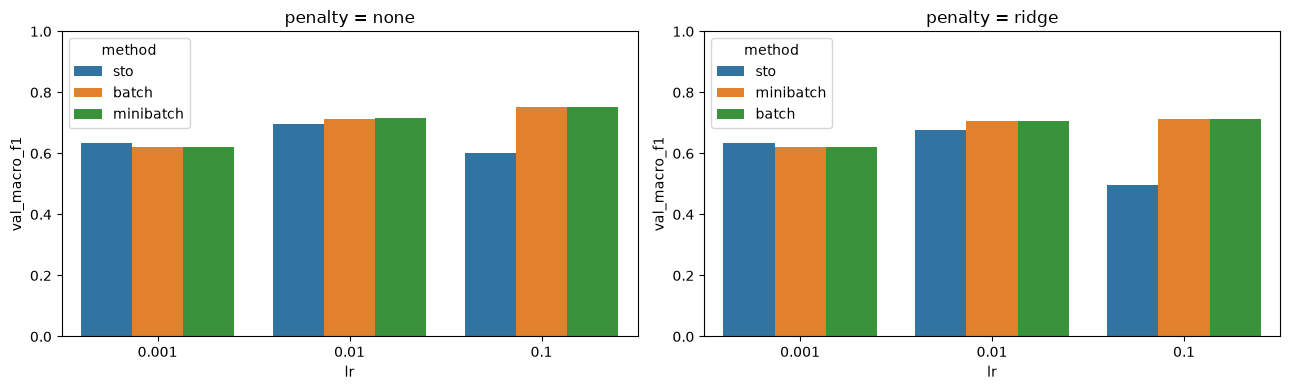

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, pen in zip(ax, ['none', 'ridge']):
    sub = results[results['penalty'] == pen]
    sns.barplot(data=sub, x='lr', y='val_macro_f1', hue='method', ax=a)
    a.set_title(f'penalty = {pen}'); a.set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 7. Register the best model (`<student_ID>-a3-model`, stage *Staging*)

In [16]:
from mlflow.tracking import MlflowClient
best = results.iloc[0]
print('best run:', best[['method', 'lr', 'penalty', 'val_macro_f1']].to_dict())

model_name = f'{STUDENT_ID}-a3-model'
version = mlflow.register_model(f"runs:/{best['run_id']}/model", model_name)
client = MlflowClient()
try:
    # classic stages (what the CSIM server shows as 'Staging')
    client.transition_model_version_stage(model_name, version.version, stage='Staging')
except Exception as e:
    print('stage transition not supported by this server:', e)
client.set_registered_model_alias(model_name, 'staging', version.version)  # newer MLflow uses aliases
print(f'registered {model_name} version {version.version} -> Staging')

best run: {'method': 'batch', 'lr': 0.1, 'penalty': 'none', 'val_macro_f1': 0.7534217218021018}
registered st127120-a3-model version 1 -> Staging


Successfully registered model 'st127120-a3-model'.
Created version '1' of model 'st127120-a3-model'.


In [17]:
# Load it back from the registry, exactly how a deployment would
staged = mlflow.pyfunc.load_model(f'models:/{model_name}@staging')
print(staged.predict(X_te[:5]), y_test[:5])

[0 0 2 3 3] [2 0 2 3 3]


## 8. Best model on the test set

In [18]:
best_model = LogisticRegression(k=4, n=X_tr.shape[1], method=best['method'], lr=best['lr'],
                                penalty=None if best['penalty'] == 'none' else 'ridge', lam=0.01)
best_model.fit(X_tr, y_train)
pred = best_model.predict(X_te)
display(best_model.classification_report(y_test, pred).round(3))

,precision,recall,f1-score,support
0,0.878,0.856,0.867,410.0
1,0.689,0.716,0.703,409.0
2,0.640,0.658,0.649,389.0
3,0.843,0.807,0.824,398.0
accuracy,NaN,NaN,0.760,1606.0
macro avg,0.762,0.759,0.761,1606.0
weighted avg,0.763,0.760,0.762,1606.0


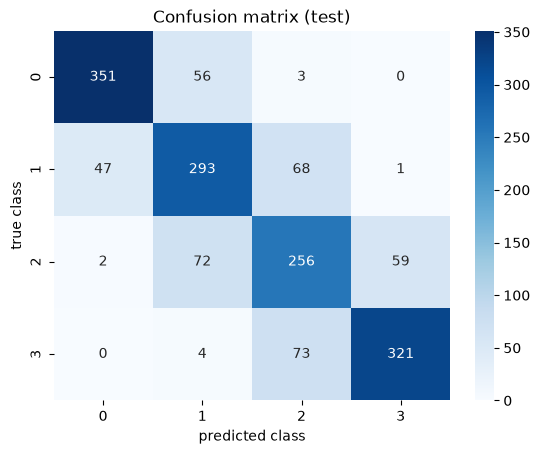

In [19]:
from sklearn.metrics import confusion_matrix
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('predicted class'); plt.ylabel('true class'); plt.title('Confusion matrix (test)'); plt.show()

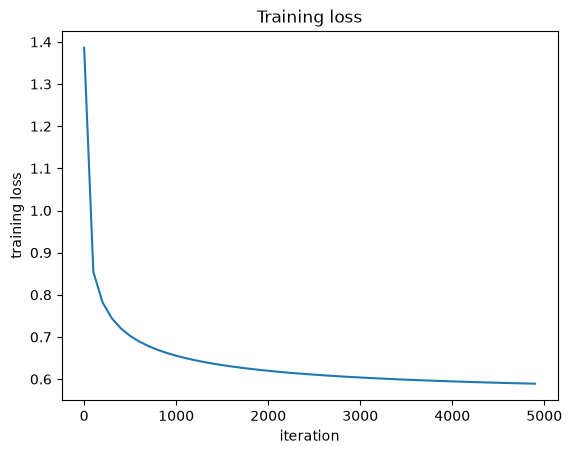

In [20]:
plt.plot(np.arange(len(best_model.losses)) * 100, best_model.losses)
plt.xlabel('iteration'); plt.ylabel('training loss'); plt.title('Training loss'); plt.show()

## 9. Save the model for the web app and the unit tests

In [21]:
os.makedirs('models_a3', exist_ok=True)
joblib.dump(best_model, 'models_a3/car_price_model.pkl')
joblib.dump(scaler, 'models_a3/scaler.pkl')
joblib.dump({'columns': feature_names, 'num_cols': num_cols, 'cat_cols': cat_cols,
             'fill_values': fill_values, 'brands': sorted(df['brand'].unique()),
             'class_edges': [float(e) for e in edges],
             'test_accuracy': float(best_model.accuracy(y_test, pred)),
             'test_macro_f1': float(best_model.macro_f1(y_test, pred))},
            'models_a3/model_columns.pkl')
print(os.listdir('models_a3'))

['model_columns.pkl', 'car_price_model.pkl', 'scaler.pkl']


## 10. Report

**Results.** The best configuration is **batch gradient descent, learning rate 0.1, no penalty**
(validation macro F1 0.753). On the test set it reaches **accuracy 0.760, macro F1 0.761, weighted F1
0.762**. Macro and weighted averages are almost identical because the quartile bins make the classes
balanced (support 389–410), so weighting by class size changes little.

**Which classes are hard?** The cheapest (class 0, F1 0.87) and most expensive (class 3, F1 0.82)
classes are easy; the middle classes 1 and 2 are hardest (F1 0.70 and 0.65). The confusion matrix
explains it: almost every mistake is between *neighbouring* classes (only 10 of 1,606 test cars are
off by two classes, none by three). A middle class has neighbours on both sides, and a car priced near
a bin edge (e.g. 445k vs the 450k cut) is close to a coin flip. Turning a continuous price into
classes throws this ordering information away, which is the main cost of treating the problem as
classification.

**Learning rate and method.** With a fixed budget of 5,000 updates, lr 0.1 works best for batch and
mini-batch; at 0.001 the model is still far from converged (macro F1 ≈ 0.62). Stochastic gradient
descent uses one car per update, so its gradients are very noisy: at lr 0.1 it bounces around
(F1 0.60) and it does best at 0.01, but it never catches up with batch in 5,000 single-sample steps.

**Ridge penalty.** With λ = 0.01 the penalty lowers macro F1 by about 3–4 points in almost every
setting. With 5,000 training cars and 40 features the model is not overfitting (validation scores are
close to training scores), so shrinking the weights only makes the fit worse. Ridge would help with
fewer samples or many more (e.g. polynomial) features; a smaller λ would also hurt less.

**MLflow.** All 18 runs, with their parameters, metrics and models, are logged to the experiment
`<student_ID>-a3`; the best one is registered as `<student_ID>-a3-model` in Staging.

In [1]:
# !python app_a3.py

In [4]:
%pip install pytest
!pytest -v tests

Note: you may need to restart the kernel to use updated packages.
============================= test session starts ==============================
platform linux -- Python 3.14.8, pytest-9.1.1, pluggy-1.7.0 -- /home/utsb/.app/Python-Venv/venv/bin/python3
cachedir: .pytest_cache
rootdir: /home/utsb/Documents/Code/ML/Project_Car_Price/A3
plugins: anyio-4.14.1, dash-4.4.1
collected 3 items                                                              

tests/test_model.py::test_model_takes_expected_input PASSED              [ 33%]
tests/test_model.py::test_model_output_shape PASSED                      [ 66%]
tests/test_model.py::test_skipped_fields_are_imputed PASSED              [100%]

============================== 3 passed in 2.17s ===============================
